# Milestone 2 — KonIQ-10k image quality regression

**Task:** predict the released continuous MOS (0–100) from one RGB photograph.
This milestone uses fully connected PyTorch networks rather than the ResNet
proposed in Milestone 1, to meet the MLP assignment.

This submission notebook includes the reusable functions and classes directly
in its cells; only report formatting uses the accompanying `m2_report.py`.
Set the dataset paths and run all cells in order to reproduce
the study. A full run trains 14 models (9 grid + 4 learning rates + 1 deep).

## Protocol and rubric decisions

- This is **regression**: class samples, label encoding, and classification
  stratification are not applicable. Show low/middle/high MOS training examples.
  The reusable splitting function supports `labels=` for stratified classification.
- Preserve the authors' **2,015 test images**. Pool the 7,058 training and 1,000
  validation images, then split 80/20: **6,446 training / 1,612 validation**.
  This explicitly changes the Milestone 1 validation protocol to meet this
  assignment. Without predefined splits, the utility uses overall 64/16/20.
- Fit RGB channel mean/std and MOS mean/std **only on the final training set**.
  Never use human rating proportions, SD, or rating counts as features.
- Select settings and epochs by maximum validation **SROCC**, consistent with
  the project objective; lower validation RMSE breaks ties. Report MAE and RMSE
  in original MOS units. Do not compare raw values of different loss functions.
- The test set is evaluated only after all selection. A single fixed seed makes
  this a controlled course comparison, not a statistical significance study.


**Setup:** install `torch`, `numpy`, `pandas`, `Pillow`, `scikit-learn`, and
`matplotlib` in your notebook environment. The raw dataset is required separately.


In [1]:
from pathlib import Path
import sys
import torch
from IPython.display import Image as IPImage, Markdown, display

# Locate the data folder from the kernel working directory.
ROOT = Path.cwd().resolve()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "data").is_dir():
        ROOT = candidate
        break

# Import only the report formatter from the notebook folder.
sys.path.insert(0, str(ROOT / "notebooks"))

# Change these paths if your dataset is stored elsewhere.
METADATA = ROOT / "data/koniq/images/KonIQ-10k/koniq10k_distributions_sets.csv"
IMAGES = ROOT / "data/koniq/images/KonIQ-10k/512x384"
OUTPUT = ROOT / "outputs/milestone2"
SEED = 42
EPOCHS = 30
BATCH_SIZE = 64
L2 = 1e-4
DEVICE = "cpu"
torch.set_num_threads(4)
print("Device:", DEVICE)
print("Project root:", ROOT)
print("Metadata:", METADATA, "(exists:", METADATA.is_file(), ")")
print("Images:", IMAGES, "(exists:", IMAGES.is_dir(), ")")


Device: cpu
Project root: /Users/mar5/vscode/ics471
Metadata: /Users/mar5/vscode/ics471/data/koniq/images/KonIQ-10k/koniq10k_distributions_sets.csv (exists: True )
Images: /Users/mar5/vscode/ics471/data/koniq/images/KonIQ-10k/512x384 (exists: True )


## 1. Data pipeline (25 points)

Convert to RGB, resize to **64×48**, scale bytes to [0,1], standardize each RGB
channel using training statistics, and flatten to **9,216** features. This keeps
the MLP tractable and preserves the 4:3 aspect ratio. Downsampling can erase fine
quality artifacts, so this is an MLP baseline rather than a state-of-the-art IQA
model. Targets are float32 tensors of shape `(batch, 1)`, standardized with
training MOS statistics. No target clipping or image augmentation is used.


In [2]:
"""Reusable, leakage-free image regression data pipeline for Milestone 2."""

from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset



IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

def find_image_paths(images_root: str | Path) -> tuple[dict[str, Path], dict[str, list[Path]]]:
    """Find images by basename and preserve collisions for the audit."""

    root = Path(images_root)
    grouped: dict[str, list[Path]] = {}
    if not root.exists():
        return {}, {}
    for path in sorted(root.rglob("*")):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            grouped.setdefault(path.name, []).append(path)
    selected = {name: paths[0] for name, paths in grouped.items()}
    collisions = {name: paths for name, paths in grouped.items() if len(paths) > 1}
    return selected, collisions


def split_indices(n, predefined=None, labels=None, seed=42):
    """Keep an official test set; split development 80/20.

    Without predefined sets, split 80/20 first (overall 64/16/20).
    For reuse with classification, pass encoded class labels to stratify BOTH
    random splits. Regression callers must leave labels=None.
    """
    indices = np.arange(n)
    labels = None if labels is None else np.asarray(labels)
    if labels is not None and len(labels) != n:
        raise ValueError("Class labels must match the number of rows")
    if predefined is None:
        development, test = train_test_split(
            indices, test_size=0.2, random_state=seed, stratify=labels
        )
    else:
        sets = np.asarray(predefined)
        if len(sets) != n or not set(sets).issubset({"training", "validation", "test"}):
            raise ValueError("Predefined sets must contain training/validation/test labels")
        test = indices[sets == "test"]
        development = indices[sets != "test"]
        if len(test) < 2:
            raise ValueError("Predefined split must contain at least two test samples")
    train, validation = train_test_split(
        development, test_size=0.2, random_state=seed,
        stratify=None if labels is None else labels[development],
    )
    # Stable metadata order also keeps saved prediction filenames aligned.
    splits = {"training": np.sort(train), "validation": np.sort(validation), "test": np.sort(test)}
    if any(len(ids) < 2 for ids in splits.values()):
        raise ValueError("Each split needs at least two samples for correlation")
    return splits


@dataclass
class Preprocessor:
    """Training-only RGB channel and target standardization statistics."""

    channel_mean: torch.Tensor
    channel_std: torch.Tensor
    target_mean: float
    target_std: float

    @classmethod
    def fit(cls, images, targets):
        # Double-precision accumulation avoids precision loss in large images.
        mean = images.double().mean(dim=(0, 2, 3), keepdim=True).float()
        std = images.double().std(dim=(0, 2, 3), correction=0, keepdim=True).float()
        target_std = float(targets.double().std(correction=0))
        if target_std < 1e-8:
            raise ValueError("Training targets must have nonzero variance")
        return cls(mean, std.clamp_min(1e-6), float(targets.double().mean()), target_std)

    def transform(self, images, targets):
        x = ((images - self.channel_mean) / self.channel_std).flatten(start_dim=1)
        y = (targets - self.target_mean) / self.target_std
        return TensorDataset(x.float(), y.float().reshape(-1, 1))

    def inverse_target(self, targets):
        return targets * self.target_std + self.target_mean

    def state_dict(self):
        return {
            "channel_mean": self.channel_mean, "channel_std": self.channel_std,
            "target_mean": self.target_mean, "target_std": self.target_std,
        }


@dataclass
class DataBundle:
    datasets: dict
    preprocessor: Preprocessor
    manifest: pd.DataFrame
    paths: dict
    image_size: tuple

    def loaders(self, batch_size=64, seed=42):
        """Fresh RNG per experiment gives identical minibatch order across runs."""
        return {
            name: DataLoader(
                dataset, batch_size=batch_size, shuffle=name == "training",
                generator=torch.Generator().manual_seed(seed), num_workers=0,
                drop_last=False,
            )
            for name, dataset in self.datasets.items()
        }


def prepare_data(metadata_path, images_root, image_size=(64, 48), seed=42):
    """Load RGB images, partition before fitting, and return PyTorch datasets.

    image_size is (width, height); 64x48 preserves the release's 4:3 ratio.
    Only pixels are inputs: rating proportions, SD, and c_total leak the target.
    Extra archive images are ignored; missing or ambiguous images fail loudly.
    """
    frame = pd.read_csv(metadata_path)
    if not {"image_name", "MOS"}.issubset(frame.columns):
        raise ValueError("Metadata requires image_name and MOS columns")
    if frame.image_name.isna().any() or frame.image_name.duplicated().any():
        raise ValueError("Image names must be present and unique")
    frame["image_name"] = frame.image_name.astype(str)
    frame["MOS"] = pd.to_numeric(frame.MOS, errors="raise")
    if not np.isfinite(frame.MOS).all() or not frame.MOS.between(0, 100).all():
        raise ValueError("Expected finite released MOS targets in [0, 100]")
    splits = split_indices(len(frame), frame["set"] if "set" in frame else None, seed=seed)
    paths, collisions = find_image_paths(images_root)
    missing = set(frame.image_name) - paths.keys()
    ambiguous = set(frame.image_name) & collisions.keys()
    if missing or ambiguous:
        raise ValueError(f"Missing {len(missing)} images; ambiguous basenames {len(ambiguous)}. "
                         f"Examples: {sorted(missing | ambiguous)[:5]}")
    if len(image_size) != 2 or min(image_size) < 1:
        raise ValueError("image_size must have two positive dimensions")
    pixels = torch.empty(len(frame), 3, image_size[1], image_size[0], dtype=torch.float32)
    for i, name in enumerate(frame.image_name):
        try:
            with Image.open(paths[name]) as image:
                rgb = ImageOps.exif_transpose(image).convert("RGB").resize(
                    image_size, Image.Resampling.BILINEAR
                )
                pixels[i] = torch.from_numpy(np.array(rgb, dtype=np.float32)).permute(2, 0, 1) / 255
        except Exception as exc:
            raise ValueError(f"Unable to decode image {name}") from exc
    targets = torch.tensor(frame.MOS.to_numpy(), dtype=torch.float32)
    preprocessor = Preprocessor.fit(pixels[splits["training"]], targets[splits["training"]])
    datasets = {
        name: preprocessor.transform(pixels[ids], targets[ids])
        for name, ids in splits.items()
    }
    manifest = frame[["image_name", "MOS"]].copy()
    if "set" in frame:
        manifest["official_set"] = frame["set"]
    manifest["split"] = ""
    for name, ids in splits.items():
        manifest.loc[ids, "split"] = name
    return DataBundle(datasets, preprocessor, manifest, paths, tuple(image_size))


def plot_samples(bundle, output_path):
    """Regression has no classes: display training examples across MOS ranks."""
    import matplotlib.pyplot as plt

    train = bundle.manifest.query("split == 'training'").sort_values("MOS")
    examples = train.iloc[[0, len(train) // 2, len(train) - 1]]
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, band, (_, row) in zip(axes, ["Low", "Middle", "High"], examples.iterrows()):
        with Image.open(bundle.paths[row.image_name]) as image:
            ax.imshow(ImageOps.exif_transpose(image).convert("RGB"))
        ax.set_title(f"{band} quality · MOS {row.MOS:.2f}")
        ax.axis("off")
    fig.suptitle("Training samples (continuous regression target; no classes)")
    fig.tight_layout()
    Path(output_path).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, dpi=160)
    plt.close(fig)


,images,mean_mos
split,,
test,2015,58.700369
training,6446,58.594748
validation,1612,59.305483


Training RGB mean: [0.4629315137863159, 0.41884106397628784, 0.3717138469219208]
Training RGB std: [0.3171231150627136, 0.30692294239997864, 0.3182825744152069]
Training MOS mean/std: 58.594748147333625 15.533188048351976
Batch shapes: torch.Size([64, 9216]) torch.Size([64, 1]) dtypes: torch.float32 torch.float32


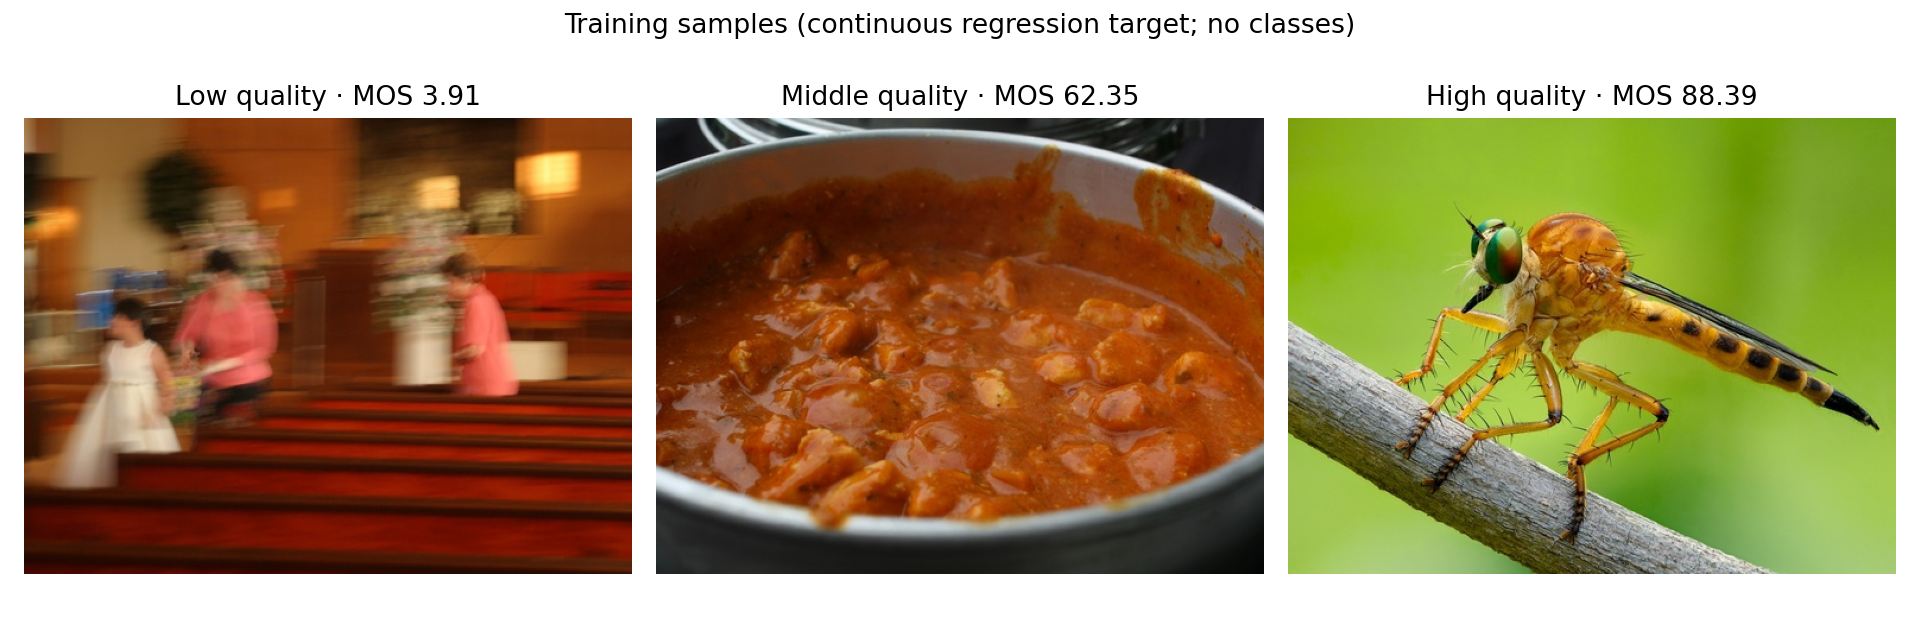

In [3]:
if not METADATA.is_file() or not IMAGES.is_dir():
    raise FileNotFoundError(
        f"Dataset paths do not exist. Kernel working directory: {Path.cwd()}\n"
        f"Metadata: {METADATA} (exists: {METADATA.is_file()})\n"
        f"Images: {IMAGES} (exists: {IMAGES.is_dir()})\n"
        "Rerun the setup cell above to refresh METADATA and IMAGES."
    )

bundle = prepare_data(METADATA, IMAGES, image_size=(64, 48), seed=SEED)
display(bundle.manifest.groupby("split").agg(images=("image_name", "size"), mean_mos=("MOS", "mean")))
print("Training RGB mean:", bundle.preprocessor.channel_mean.flatten().tolist())
print("Training RGB std:", bundle.preprocessor.channel_std.flatten().tolist())
print("Training MOS mean/std:", bundle.preprocessor.target_mean, bundle.preprocessor.target_std)
loaders = bundle.loaders(BATCH_SIZE, SEED)
x, y = next(iter(loaders["training"]))
print("Batch shapes:", x.shape, y.shape, "dtypes:", x.dtype, y.dtype)
SAMPLE_FIGURE = ROOT / "outputs/milestone2_preview/samples.png"
plot_samples(bundle, SAMPLE_FIGURE)
display(IPImage(filename=str(SAMPLE_FIGURE)))

## 2. Flexible MLP (12 points)

The shallow network has **256 and 128** hidden neurons. The first layer compresses
9,216 input pixels into a manageable representation; the second reduces capacity
to limit overfitting. The deeper network has exactly **256, 128, 64, 32, 16** hidden
neurons. Keeping the first two widths fixes the dominant input-layer capacity;
the additional tapered layers test added depth with a modest parameter increase.

Every hidden layer uses **ReLU**, an inexpensive nonlinearity without sigmoid's
positive-side saturation. Both networks end with **one linear output**, suitable
for a standardized continuous target (which can be negative). No softmax/sigmoid.
The builder accepts arbitrary hidden widths, output width, and activation class.


In [4]:
"""Configurable fully connected networks, regression losses, and optimizers."""

from torch import nn
from torch.optim import SGD, Adam, RMSprop

SHALLOW = (256, 128)
DEEP = (256, 128, 64, 32, 16)
LOSSES = ("mse", "mae", "huber")
OPTIMIZERS = ("sgd", "rmsprop", "adam")


class MLP(nn.Module):
    """Any number of hidden layers; linear outputs support regression.

    ReLU avoids sigmoid/tanh saturation and is inexpensive. A tapering width
    controls parameters for flattened images. The deep model retains the first
    two widths so extra depth is the main architecture change.
    """

    def __init__(self, input_dim, hidden_dims=SHALLOW, output_dim=1, activation=nn.ReLU):
        super().__init__()
        if not hidden_dims or any(width < 1 for width in (input_dim, *hidden_dims, output_dim)):
            raise ValueError("All layer widths must be positive; provide hidden layers")
        layers = []
        previous = input_dim
        for width in hidden_dims:
            layers.extend([nn.Linear(previous, width), activation()])
            previous = width
        layers.append(nn.Linear(previous, output_dim))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x.flatten(start_dim=1))


def make_loss(name):
    """Huber delta=1 is one training-target standard deviation."""
    factories = {"mse": nn.MSELoss, "mae": nn.L1Loss, "huber": lambda: nn.HuberLoss(delta=1.0)}
    if name not in factories:
        raise ValueError(f"Unknown loss {name}; choose {tuple(factories)}")
    return factories[name]()


def make_optimizer(name, parameters, lr):
    """Explicit L2 is added to the objective in training, uniformly for all three."""
    factories = {
        "sgd": lambda: SGD(parameters, lr=lr, momentum=0.9),
        "rmsprop": lambda: RMSprop(parameters, lr=lr, alpha=0.99),
        "adam": lambda: Adam(parameters, lr=lr),
    }
    if name not in factories:
        raise ValueError(f"Unknown optimizer {name}; choose {tuple(factories)}")
    return factories[name]()


In [5]:
input_dim = bundle.datasets["training"].tensors[0].shape[1]
for name, widths in [("shallow", SHALLOW), ("deep", DEEP)]:
    model = MLP(input_dim, widths)
    print(name, model)
    print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

shallow MLP(
  (network): Sequential(
    (0): Linear(in_features=9216, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)
Trainable parameters: 2392577
deep MLP(
  (network): Sequential(
    (0): Linear(in_features=9216, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): ReLU()
    (10): Linear(in_features=16, out_features=1, bias=True)
  )
)
Trainable parameters: 2403329


## 3. Required experiments (53 points)

**Losses:** MSE emphasizes large errors; MAE is less influenced by large errors;
Huber combines quadratic behavior near zero with linear tails (`delta=1`, one
training MOS standard deviation). All operate on standardized MOS.

**Regularization:** fixed explicit L2 strength **λ = 10⁻⁴** on weight matrices,
excluding biases: `objective = mean_data_loss + (λ/2) × Σ weight²`. Optimizer
weight decay is zero to apply the same defined penalty across optimizers.

**Optimizers:** SGD with momentum 0.9; RMSprop with alpha 0.99; Adam with default
betas (0.9, 0.999). Run the full **3×3** at learning rate **0.001**, then test
**0.0001, 0.0003, 0.001, 0.003** for the selected pair. Train the deep model with
that pair and the selected rate. Same seed, batch order, regularization and
30-epoch budget for every trial; restore each best validation checkpoint.

The execution cell runs the complete study, prints progress after each trial,
and saves every trial's best validation checkpoint. The same
`outputs/milestone2/` folder is reused on reruns. Tables stay in memory;
the report formatter is imported from `m2_report.py`.


### Reusable training and experiment runner

The following cell defines `train_model`, `Trial`, the evaluation helpers,
and the complete experiment runner. These functions and classes can be
reused by other notebooks or scripts.


In [6]:
"""Reusable training and evaluation with validation-only checkpoint selection."""

import random
from dataclasses import dataclass

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader



def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)


def regression_metrics(targets, predictions):
    """Metrics in original MOS units. Constant predictions have undefined SROCC."""
    targets = np.asarray(targets, dtype=np.float64).ravel()
    predictions = np.asarray(predictions, dtype=np.float64).ravel()
    if not np.isfinite(targets).all() or not np.isfinite(predictions).all():
        raise FloatingPointError("Nonfinite regression target/prediction")
    error = predictions - targets
    ranks_y = pd.Series(targets).rank().to_numpy()
    ranks_p = pd.Series(predictions).rank().to_numpy()
    srocc = float("nan")
    if np.std(ranks_y) > 0 and np.std(ranks_p) > 0:
        srocc = float(np.corrcoef(ranks_y, ranks_p)[0, 1])
    return {"mae": float(np.mean(np.abs(error))),
            "rmse": float(np.sqrt(np.mean(error ** 2))), "srocc": srocc}


def selection_key(metrics):
    """Higher SROCC wins; lower RMSE breaks ties. Undefined SROCC ranks last."""
    score = metrics["srocc"]
    return (score if np.isfinite(score) else -float("inf"), -metrics["rmse"])


@torch.no_grad()
def evaluate(model, loader, criterion, preprocessor, device):
    model.eval()
    predictions, targets = [], []
    loss_sum = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        predicted = model(x)
        loss_sum += float(criterion(predicted, y)) * len(x)
        predictions.append(predicted.cpu())
        targets.append(y.cpu())
    predictions = preprocessor.inverse_target(torch.cat(predictions)).numpy().ravel()
    targets = preprocessor.inverse_target(torch.cat(targets)).numpy().ravel()
    metrics = regression_metrics(targets, predictions)
    metrics["loss"] = loss_sum / len(loader.dataset)
    if not np.isfinite(metrics["loss"]):
        raise FloatingPointError("Nonfinite evaluation loss")
    return metrics, targets, predictions


@dataclass
class Trial:
    model: MLP
    history: pd.DataFrame
    best_epoch: int
    validation: dict
    settings: dict


def train_model(bundle, hidden_dims, loss_name, optimizer_name, lr,
                epochs=30, batch_size=64, l2=1e-4, seed=42, device="cpu"):
    """Fit only training data; select epoch by validation SROCC, never test.

    Objective = mean data loss + (l2 / 2) * sum(weight**2).
    Biases are excluded. Optimizer weight_decay stays zero so this exact penalty
    is consistent across SGD, RMSprop, and Adam. Plots show unpenalized data loss.
    Every epoch's train/validation metrics use the same end-of-epoch model.
    """
    if epochs < 1 or batch_size < 1 or lr <= 0 or l2 < 0:
        raise ValueError("epochs/batch_size/lr must be positive and l2 nonnegative")
    seed_everything(seed)
    loaders = bundle.loaders(batch_size, seed)
    # Evaluation must not advance the training shuffle generator.
    train_evaluation = DataLoader(bundle.datasets["training"], batch_size=batch_size)
    input_dim = bundle.datasets["training"].tensors[0].shape[1]
    model = MLP(input_dim, hidden_dims).to(device)
    criterion = make_loss(loss_name)
    optimizer = make_optimizer(optimizer_name, model.parameters(), lr)
    history, best_state, best_metrics, best_epoch = [], None, None, None
    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in loaders["training"]:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            data_loss = criterion(model(x), y)
            penalty = 0.5 * l2 * sum(p.square().sum() for p in model.parameters() if p.ndim > 1)
            objective = data_loss + penalty
            if not torch.isfinite(objective):
                raise FloatingPointError(f"Training diverged at epoch {epoch}")
            objective.backward()
            optimizer.step()
        train_metrics, _, _ = evaluate(model, train_evaluation, criterion, bundle.preprocessor, device)
        validation, _, _ = evaluate(model, loaders["validation"], criterion, bundle.preprocessor, device)
        history.append({"epoch": epoch,
                        **{f"train_{k}": v for k, v in train_metrics.items()},
                        **{f"val_{k}": v for k, v in validation.items()}})
        if best_metrics is None or selection_key(validation) > selection_key(best_metrics):
            best_metrics, best_epoch = validation, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    settings = dict(input_dim=input_dim, hidden_dims=list(hidden_dims), loss=loss_name,
                    optimizer=optimizer_name, lr=lr, epochs=epochs, batch_size=batch_size,
                    l2=l2, seed=seed, device=str(device))
    return Trial(model, pd.DataFrame(history), best_epoch, best_metrics, settings)


import matplotlib.pyplot as plt
from m2_report import build_report


def plot_history(trial, path, title):
    history = trial.history
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, metric, label in zip(axes, ["loss", "mae", "srocc"],
                                 ["Data loss (standardized target)", "MAE (MOS)", "SROCC"]):
        ax.plot(history.epoch, history[f"train_{metric}"], label="Training")
        ax.plot(history.epoch, history[f"val_{metric}"], label="Validation")
        ax.axvline(trial.best_epoch, color="gray", linestyle=":", label="Selected epoch")
        ax.set(xlabel="Epoch", ylabel=label)
        ax.grid(alpha=0.2)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=160)
    plt.close(fig)


def save_trial(trial, bundle, directory):
    directory.mkdir(parents=True, exist_ok=True)
    torch.save({"model_state": {k: v.detach().cpu() for k, v in trial.model.state_dict().items()},
                "settings": trial.settings, "best_epoch": trial.best_epoch,
                "preprocessor": bundle.preprocessor.state_dict(),
                "image_size": bundle.image_size}, directory / "checkpoint.pt")


def trial_row(trial, run_id):
    return {"run": run_id, "loss": trial.settings["loss"],
            "optimizer": trial.settings["optimizer"], "lr": trial.settings["lr"],
            "best_epoch": trial.best_epoch,
            **{f"val_{k}": v for k, v in trial.validation.items()},
            "parameters": sum(p.numel() for p in trial.model.parameters()), "status": "ok"}


def run_experiments(bundle, output_dir, epochs=30, batch_size=64, l2=1e-4,
                    seed=42, device="cpu", base_lr=1e-3,
                    learning_rates=(1e-4, 3e-4, 1e-3, 3e-3)):
    """Run the full study, saving every trial's best validation checkpoint."""
    if len(learning_rates) != 4 or len(set(learning_rates)) != 4 or min(learning_rates) <= 0:
        raise ValueError("Provide exactly four distinct positive learning rates")
    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=True)
    plot_samples(bundle, output / "samples.png")

    def fit(run_id, hidden, loss, optimizer, lr):
        print(f"Training {run_id}: {loss}, {optimizer}, lr={lr:g}", flush=True)
        trial = train_model(bundle, hidden, loss, optimizer, lr, epochs,
                            batch_size, l2, seed, device)
        save_trial(trial, bundle, output / run_id)
        print(f"  epoch={trial.best_epoch}; validation SROCC={trial.validation['srocc']:.4f}; "
              f"MAE={trial.validation['mae']:.4f}", flush=True)
        return trial

    def sweep(specifications):
        rows, best = [], None
        for run_id, loss, optimizer, lr in specifications:
            try:
                trial = fit(run_id, SHALLOW, loss, optimizer, lr)
                rows.append(trial_row(trial, run_id))
                if best is None or selection_key(trial.validation) > selection_key(best.validation):
                    best = trial
            except FloatingPointError as exc:
                rows.append(dict(run=run_id, loss=loss, optimizer=optimizer, lr=lr,
                                 status=f"failed: {exc}"))
                print(f"  FAILED: {exc}", flush=True)
        if best is None:
            raise RuntimeError("All trials failed; inspect the progress output")
        return pd.DataFrame(rows), best

    grid, best_pair = sweep(
        [(f"grid_{loss}_{opt}", loss, opt, base_lr) for loss in LOSSES for opt in OPTIMIZERS],
    )
    loss, optimizer = best_pair.settings["loss"], best_pair.settings["optimizer"]
    lr_table, shallow = sweep(
        [(f"lr_{i}", loss, optimizer, lr) for i, lr in enumerate(learning_rates)],
    )
    deep = fit("deep", DEEP, loss, optimizer, shallow.settings["lr"])
    save_trial(shallow, bundle, output / "shallow")
    # All architecture/hyperparameter/epoch choices are now locked.
    test_loader = bundle.loaders(batch_size, seed)["test"]
    test_rows = []
    for name, trial in [("shallow", shallow), ("deep", deep)]:
        metrics, targets, predictions = evaluate(
            trial.model, test_loader, make_loss(loss), bundle.preprocessor, device
        )
        test_rows.append(dict(network=name, hidden_layers=len(trial.settings["hidden_dims"]),
                              parameters=sum(p.numel() for p in trial.model.parameters()),
                              best_epoch=trial.best_epoch, **metrics))
        plot_history(trial, output / f"{name}_curves.png", f"{name.title()} MLP · {loss}/{optimizer}")
    baseline = regression_metrics(targets, np.full_like(targets, bundle.preprocessor.target_mean))
    test_rows.append(dict(network="training-mean baseline", hidden_layers=0, parameters=0,
                          best_epoch=0, **baseline))
    tests = pd.DataFrame(test_rows)
    split_policy = ("official test held out; remaining pool split 80/20"
                    if "official_set" in bundle.manifest else "random 64/16/20")
    report = build_report(
        grid, lr_table, tests, shallow=shallow, deep=deep,
        image_size=bundle.image_size, split_policy=split_policy,
        epochs=epochs, batch_size=batch_size, l2=l2, seed=seed,
        device=device, base_lr=base_lr,
    )
    (output / "report.md").write_text(report)
    return {"grid": grid, "learning_rates": lr_table, "test": tests, "output_dir": output}


### Run the complete study

This runs all 14 models on your dataset. Results are saved and displayed below.

In [7]:
print("Saving this run to:", OUTPUT)

results = run_experiments(
    bundle, OUTPUT, epochs=EPOCHS, batch_size=BATCH_SIZE, l2=L2,
    seed=SEED, device=DEVICE, base_lr=1e-3,
    learning_rates=(1e-4, 3e-4, 1e-3, 3e-3),
)


Saving this run to: /Users/mar5/vscode/ics471/outputs/milestone2


Training grid_mse_sgd: mse, sgd, lr=0.001


  epoch=5; validation SROCC=0.4720; MAE=10.3642


Training grid_mse_rmsprop: mse, rmsprop, lr=0.001


  epoch=25; validation SROCC=0.4443; MAE=11.8855


...

  epoch=5; validation SROCC=0.4720; MAE=10.3642


Training lr_3: mse, sgd, lr=0.003


  epoch=3; validation SROCC=0.4768; MAE=10.4104


Training deep: mse, sgd, lr=0.003


  epoch=7; validation SROCC=0.4871; MAE=10.2995


### Complete 3×3 comparison — validation metrics

In [8]:
display(results["grid"])
display(results["grid"].pivot(index="loss", columns="optimizer", values="val_srocc"))

,run,loss,optimizer,lr,best_epoch,val_mae,val_rmse,val_srocc,val_loss,parameters,status
0,grid_mse_sgd,mse,sgd,0.001,5,10.364235,13.078497,0.472022,0.708916,2392577,ok
1,grid_mse_rmsprop,mse,rmsprop,0.001,25,11.885541,14.653464,0.444314,0.889937,2392577,ok
2,grid_mse_adam,mse,adam,0.001,5,10.788479,13.663840,0.424185,0.773792,2392577,ok
3,grid_mae_sgd,mae,sgd,0.001,21,10.888782,14.079332,0.453358,0.701001,2392577,ok
4,grid_mae_rmsprop,mae,rmsprop,0.001,11,10.903009,13.915334,0.415713,0.701917,2392577,ok
5,grid_mae_adam,mae,adam,0.001,7,10.729232,13.605884,0.434509,0.690730,2392577,ok
6,grid_huber_sgd,huber,sgd,0.001,10,10.379551,13.131945,0.468479,0.314653,2392577,ok
7,grid_huber_rmsprop,huber,rmsprop,0.001,11,10.997478,13.827078,0.412682,0.346663,2392577,ok
8,grid_huber_adam,huber,adam,0.001,21,11.317755,14.366861,0.421734,0.368163,2392577,ok


optimizer,adam,rmsprop,sgd
loss,,,
huber,0.421734,0.412682,0.468479
mae,0.434509,0.415713,0.453358
mse,0.424185,0.444314,0.472022


### Four learning rates — selected loss/optimizer

In [9]:
display(results["learning_rates"])

,run,loss,optimizer,lr,best_epoch,val_mae,val_rmse,val_srocc,val_loss,parameters,status
0,lr_0,mse,sgd,0.0001,25,10.498147,13.180994,0.458405,0.720071,2392577,ok
1,lr_1,mse,sgd,0.0003,10,10.608906,13.208949,0.460366,0.723128,2392577,ok
2,lr_2,mse,sgd,0.0010,5,10.364235,13.078497,0.472022,0.708916,2392577,ok
3,lr_3,mse,sgd,0.0030,3,10.410415,13.074619,0.476817,0.708495,2392577,ok


### Final shallow versus deep comparison — held-out test set

In [10]:
display(results["test"])
test = results["test"].set_index("network")
print("Deep minus shallow test SROCC:", test.loc["deep", "srocc"] - test.loc["shallow", "srocc"])
print("Deep minus shallow test MAE:", test.loc["deep", "mae"] - test.loc["shallow", "mae"])
print("Higher SROCC and lower MAE/RMSE are better. Do not retune using these test results.")

,network,hidden_layers,parameters,best_epoch,mae,rmse,srocc,loss
0,shallow,2,2392577,3,10.655842,13.485918,0.471036,0.753772
1,deep,5,2403329,7,10.451660,13.253497,0.479005,0.728014
2,training-mean baseline,0,0,0,12.511141,15.424191,NaN,NaN


Deep minus shallow test SROCC: 0.007968651552394401
Deep minus shallow test MAE: -0.20418218986567993
Higher SROCC and lower MAE/RMSE are better. Do not retune using these test results.


## 4. Required plots (10 points)

Both networks: training and validation **loss versus epoch**, and training and
validation **MAE/SROCC versus epoch**. Loss excludes L2 and is evaluated at the
same epoch-end model for both splits. MAE is converted back to original MOS
units. The selected checkpoint is marked by a dotted line.


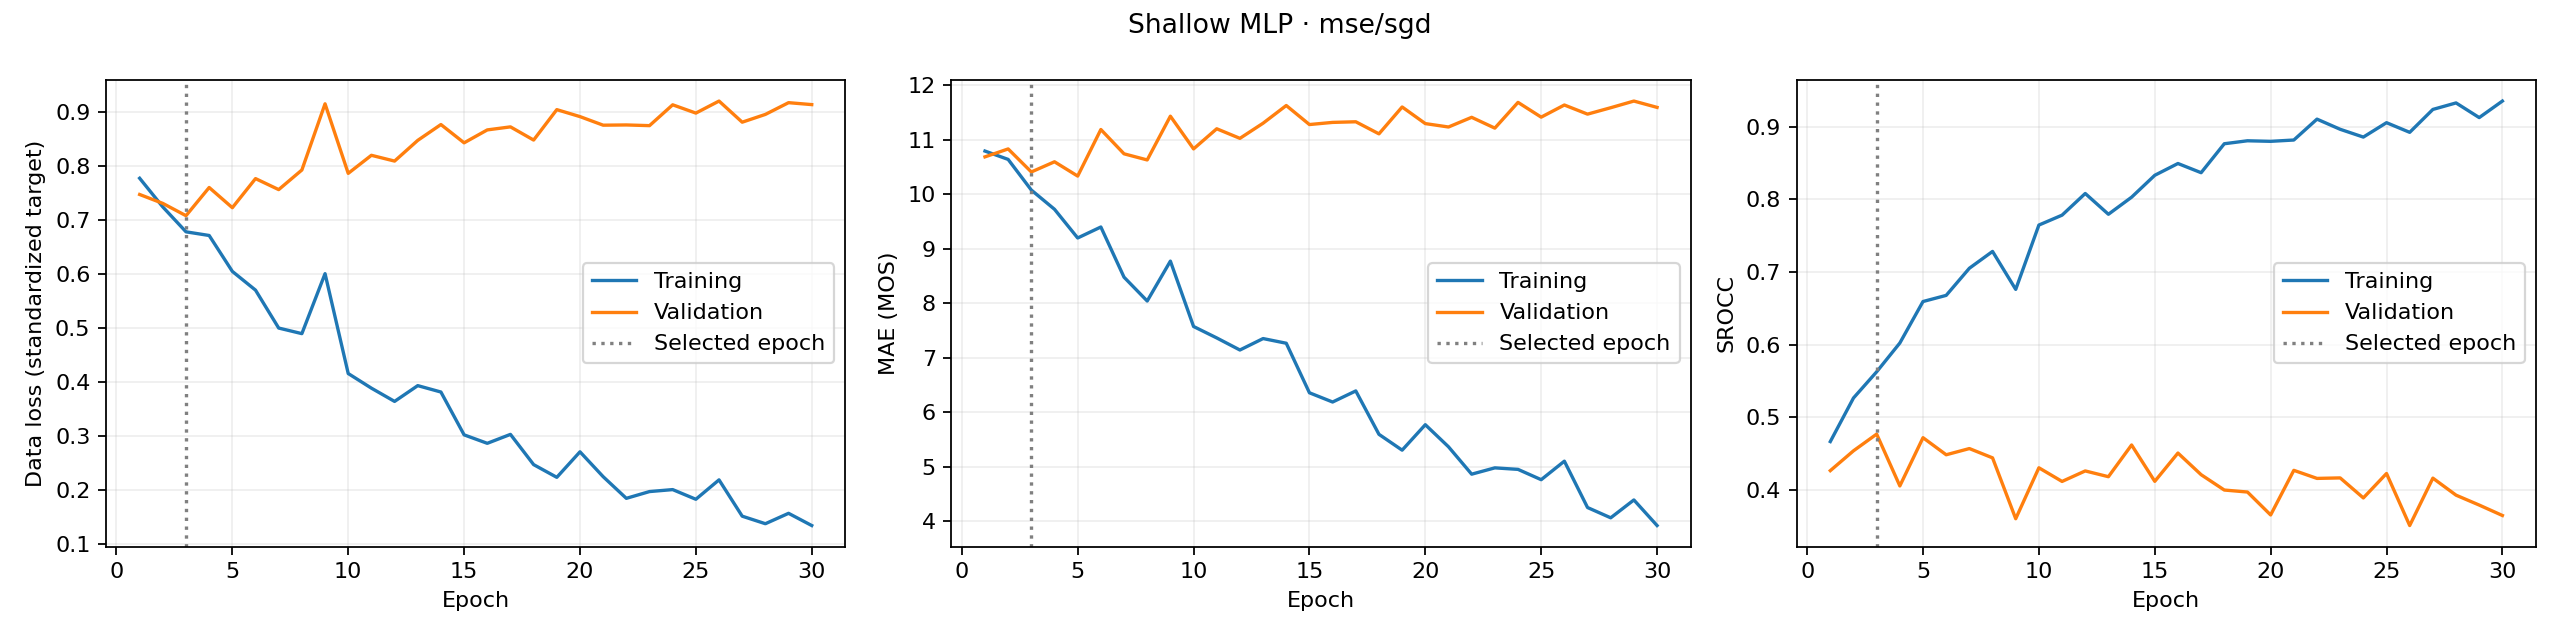

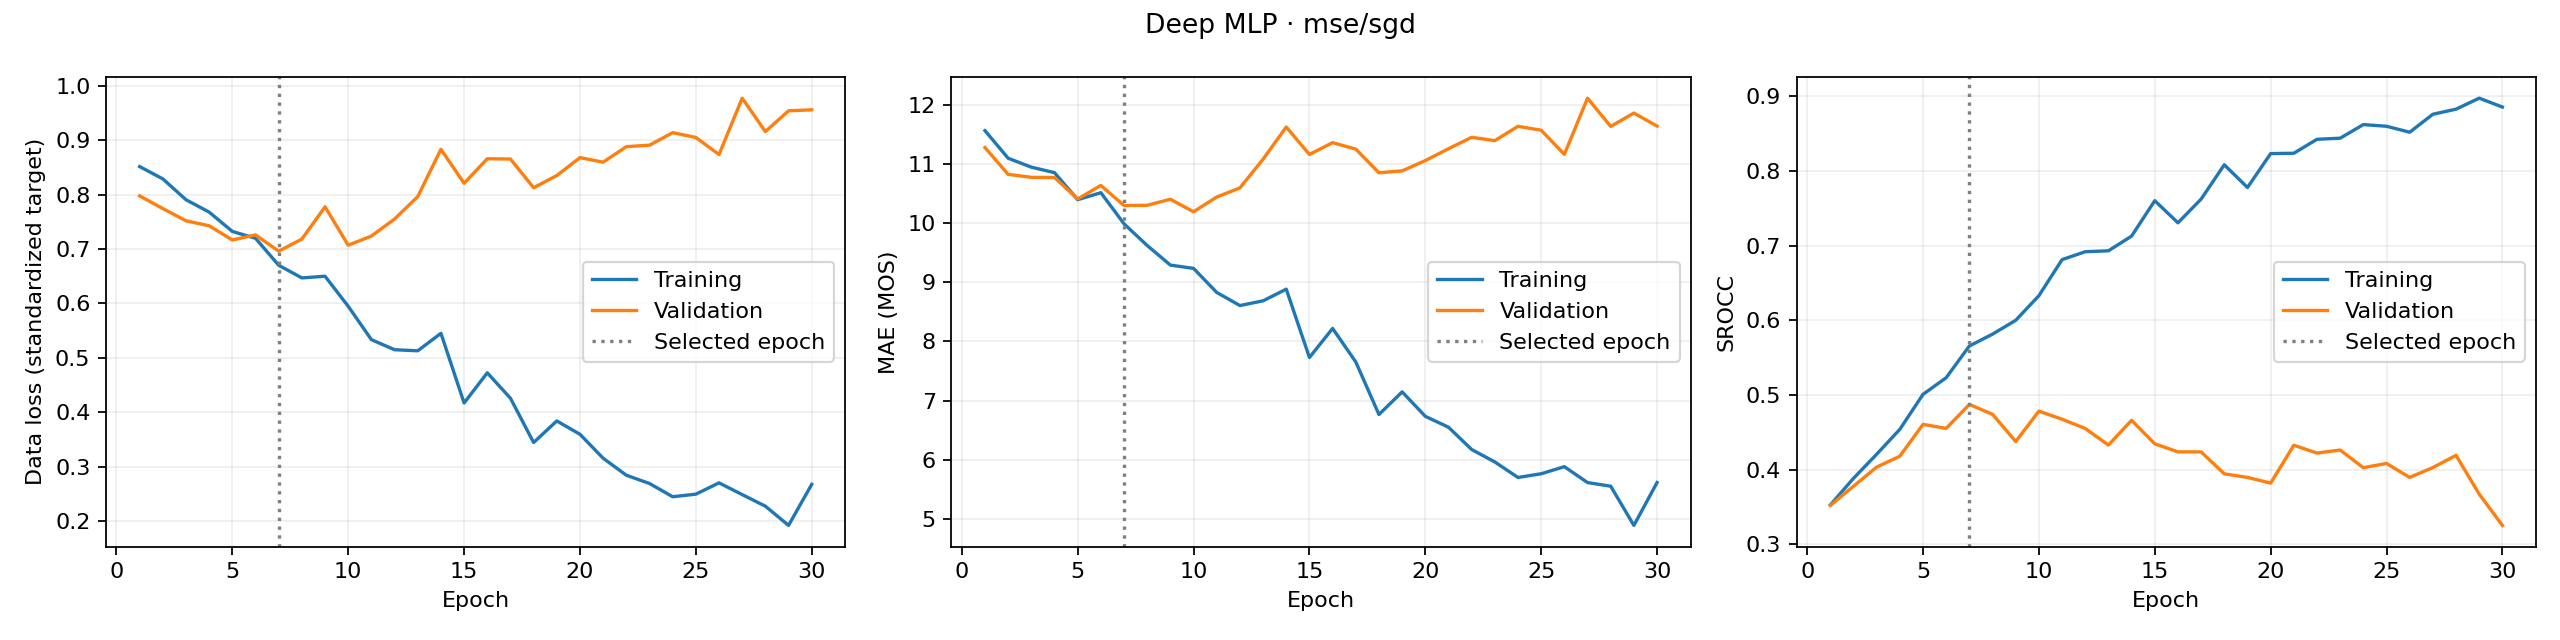

In [11]:
for name in ("shallow", "deep"):
    display(IPImage(filename=str(OUTPUT / f"{name}_curves.png")))

### Generated Markdown report


In [12]:
display(Markdown((OUTPUT / "report.md").read_text().split("## Required learning curves")[0]))
print("Saved report, plots, and trial checkpoints:", OUTPUT)


# Milestone 2: KonIQ-10k MLP regression

## Protocol
Seed 42; 30 epochs per trial; batch size 64; device cpu.
Split policy: official test held out; remaining pool split 80/20.
RGB images resize to (64, 48), scale to [0,1], and use training-only
channel standardization. MOS targets use training-only mean/std normalization.
No rating-derived metadata is used as input. There are no classification labels;
stratification and class encoding are inapplicable. Samples span training MOS ranks.

Shallow hidden widths: (256, 128); deep hidden widths: (256, 128, 64, 32, 16). ReLU hidden
activations provide inexpensive nonlinearities; the linear scalar output predicts
standardized MOS without clipping. The taper limits model size. Resizing reduces
compute but can remove subtle quality artifacts, a limitation of this baseline.

Explicit L2 strength is **0.0001**: objective = mean data loss + lambda/2 times
the sum of squared weights (biases excluded). Optimizer weight decay is zero.
MSE emphasizes large errors; MAE reduces their influence; Huber (delta=1 in
standardized MOS) combines quadratic and linear behavior. SGD momentum=0.9;
RMSprop alpha=0.99; Adam uses PyTorch defaults. All trials use the same splits,
initialization seed, batch order, epoch budget, and regularization.

## 3 × 3 loss/optimizer comparison
Base learning rate: 0.001. Epochs and combinations are chosen by maximum
validation SROCC, then minimum RMSE for ties. Loss magnitudes across different
loss functions are not directly comparable. Undefined SROCC ranks last.

| run | loss | optimizer | lr | best_epoch | val_mae | val_rmse | val_srocc | val_loss | parameters | status |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| grid_mse_sgd | mse | sgd | 0.001 | 5 | 10.3642 | 13.0785 | 0.472022 | 0.708916 | 2392577 | ok |
| grid_mse_rmsprop | mse | rmsprop | 0.001 | 25 | 11.8855 | 14.6535 | 0.444314 | 0.889937 | 2392577 | ok |
| grid_mse_adam | mse | adam | 0.001 | 5 | 10.7885 | 13.6638 | 0.424185 | 0.773792 | 2392577 | ok |
| grid_mae_sgd | mae | sgd | 0.001 | 21 | 10.8888 | 14.0793 | 0.453358 | 0.701001 | 2392577 | ok |
| grid_mae_rmsprop | mae | rmsprop | 0.001 | 11 | 10.903 | 13.9153 | 0.415713 | 0.701917 | 2392577 | ok |
| grid_mae_adam | mae | adam | 0.001 | 7 | 10.7292 | 13.6059 | 0.434509 | 0.69073 | 2392577 | ok |
| grid_huber_sgd | huber | sgd | 0.001 | 10 | 10.3796 | 13.1319 | 0.468479 | 0.314653 | 2392577 | ok |
| grid_huber_rmsprop | huber | rmsprop | 0.001 | 11 | 10.9975 | 13.8271 | 0.412682 | 0.346663 | 2392577 | ok |
| grid_huber_adam | huber | adam | 0.001 | 21 | 11.3178 | 14.3669 | 0.421734 | 0.368163 | 2392577 | ok |

## Four learning rates
Selected pair: **mse + sgd**.

| run | loss | optimizer | lr | best_epoch | val_mae | val_rmse | val_srocc | val_loss | parameters | status |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| lr_0 | mse | sgd | 0.0001 | 25 | 10.4981 | 13.181 | 0.458405 | 0.720071 | 2392577 | ok |
| lr_1 | mse | sgd | 0.0003 | 10 | 10.6089 | 13.2089 | 0.460366 | 0.723128 | 2392577 | ok |
| lr_2 | mse | sgd | 0.001 | 5 | 10.3642 | 13.0785 | 0.472022 | 0.708916 | 2392577 | ok |
| lr_3 | mse | sgd | 0.003 | 3 | 10.4104 | 13.0746 | 0.476817 | 0.708495 | 2392577 | ok |

Selected learning rate: **0.003**.

## Held-out test comparison
The same selected loss, optimizer and learning rate are used for both networks.
Each network restores its own best validation epoch. MAE/RMSE are in original
MOS units. The constant training-mean baseline has undefined SROCC by definition.

| network | hidden_layers | parameters | best_epoch | mae | rmse | srocc | loss |
| --- | --- | --- | --- | --- | --- | --- | --- |
| shallow | 2 | 2392577 | 3 | 10.6558 | 13.4859 | 0.471036 | 0.753772 |
| deep | 5 | 2403329 | 7 | 10.4517 | 13.2535 | 0.479005 | 0.728014 |
| training-mean baseline | 0 | 0 | 0 | 12.5111 | 15.4242 | nan | nan |

Deep minus shallow validation SROCC: 0.010324.
Deep minus shallow test SROCC: 0.007969.
Deep minus shallow test MAE: -0.204182.
Positive SROCC differences favor deep; negative MAE differences favor deep.
These are single-seed results, not evidence of statistical significance. Test
results are reported after selection and must not be used to retune this study.



Saved report, plots, and trial checkpoints: /Users/mar5/vscode/ics471/outputs/milestone2


### Limitations and sources

A flattened pixel MLP does not explicitly exploit spatial locality, and resizing
may remove blur/noise cues. Depth alone need not improve generalization. Interpret
the test comparison as one controlled run. Repeating seeds would estimate
variability, but is outside the required comparison.

- [Authors' KonIQ metadata](https://github.com/subpic/koniq/tree/master/metadata)
- [PyTorch HuberLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.HuberLoss.html)

**Submission note:** The reusable data pipeline, model, training, and experiment
code is visible in this notebook. Only Markdown report formatting is imported
from `m2_report.py`; include that file beside the notebook when rerunning.
Our modular implementation is also available in the
[repository](https://github.com/mar5-a/ics471-koniq10k).
All experiment outputs below were regenerated by executing this notebook
on the real KonIQ-10k dataset.
